# 01 · Data preprocessing

This notebook turns the raw FiGraph files into clean tables, one row per company-year.
Run it first, then `02_feature_engineering.ipynb`.

| Section | Reads | Writes (in `data/processed/`) | Time |
|---|---|---|---|
| 1. Clean the tabular features | `data/<year>/ListedCompanyFeatures772_<year>.csv` | `tabular_clean/`, `cleaning_log.csv` | ~5 s |
| 2. Load the MD&A text | `data/<year>/MDA_<year>*.xlsx` | `mda_raw.parquet` | ~30 s |
| 3. Clean and split the MD&A text | `mda_raw.parquet`, `data/stopwords/`, `data/sentiment/` | `mda_clean/` | ~20 min |

All outputs here are gitignored (too large for GitHub). Running the notebook top to bottom recreates them.

Each section has three parts: the code, a cell that runs it, and a chart of what it produced.

In [1]:
from pathlib import Path
import re
import time
import unicodedata

import jieba
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.compute as pc
import pyarrow.parquet as pq

In [2]:
# Works whether the notebook is run from notebook/ (Jupyter) or from the repo root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
DATA_DIR = ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
YEARS = range(2014, 2023)


# One chart style for the whole notebook (validated categorical palette, slots 1-3).
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, GRID, MUTED = "#0b0b0b", "#52514e", "#e6e5e1", "#b8b7b1"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK_2, "ytick.color": INK_2, "font.size": 9.5,
    "legend.frameon": False, "lines.linewidth": 2,
})

## 1. Clean the tabular features

1. **Stack** the nine yearly CSV files into one table.
2. **Check** it: same columns every year, one row per `nodeID` + `Year`, `Label` is 0 or 1.
3. **Fill blanks with 0** in financial statement items. 2014–2015 store "not reported" as 0, later years leave it blank, so the blanks also mean 0.
4. **Fill 12 missing industry codes** from the same company's nearest year.
5. **Drop 106 columns:** 7 that never change and 99 exact copies of another column.

What's still missing (about 2.5% of cells) stays empty. Filling it needs the training years, so it happens in notebook 02, per split.

In [3]:
TAB_RAW_DIR = ROOT / "data"
TAB_OUT_DIR = TAB_RAW_DIR / "processed"

TAB_KEYS = ["nodeID", "Year", "Label"]
# Raw financial statement line items: A = balance sheet, B = income statement,
# C = cash flow statement (direct), D = cash flow statement (indirect).
TAB_STATEMENT_COL = re.compile(r"[A-D][0-9A-Za-z]{2}\d{7}")
TAB_STATEMENT_NAMES = {
    "A": "balance sheet",
    "B": "income statement",
    "C": "cash flow (direct)",
    "D": "cash flow (indirect)",
}


def tab_load_raw() -> pd.DataFrame:
    frames = []
    columns = None
    for year in YEARS:
        frame = pd.read_csv(
            TAB_RAW_DIR / str(year) / f"ListedCompanyFeatures772_{year}.csv",
            low_memory=False,
        )
        if columns is None:
            columns = list(frame.columns)
        assert list(frame.columns) == columns, f"{year}: columns differ from 2014"
        assert (frame["Year"] == year).all(), f"{year}: Year column disagrees with file"
        frames.append(frame)
    return pd.concat(frames, ignore_index=True)


def tab_check_keys(df: pd.DataFrame) -> None:
    assert df["nodeID"].str.fullmatch(r"L\d{6}").all(), "unexpected nodeID format"
    assert not df.duplicated(["nodeID", "Year"]).any(), "duplicate company-year rows"
    assert df["Label"].isin([0, 1]).all(), "Label must be 0/1"


def column_group(col: str) -> str:
    if TAB_STATEMENT_COL.fullmatch(col):
        return TAB_STATEMENT_NAMES[col[0]]
    if col == "IndustryCodeC":
        return "categorical"
    return "ratio / other"


def harmonise_statement_zeros(df: pd.DataFrame, statement_cols: list[str]) -> None:
    """Make "item not reported" mean 0 in every year.

    The 2014-2015 files (and ~8% of 2016) store an unreported statement line
    item as 0; later files leave it blank. The share of non-zero values is the
    same either way, so the blanks are zeros, not unknowns. A blank is only
    kept when the company has no values at all for that statement that year.
    """
    for prefix in TAB_STATEMENT_NAMES:
        cols = [c for c in statement_cols if c[0] == prefix]
        has_statement = df[cols].notna().any(axis=1)
        df.loc[has_statement, cols] = df.loc[has_statement, cols].fillna(0.0)


def fill_industry(df: pd.DataFrame) -> int:
    """Fill a missing industry code from the same company's nearest year."""
    missing = int(df["IndustryCodeC"].isna().sum())
    df["IndustryCodeC"] = df.groupby("nodeID")["IndustryCodeC"].transform(
        lambda s: s.ffill().bfill()
    )
    return missing


def find_redundant(df: pd.DataFrame, features: list[str]) -> dict[str, str]:
    """Return {column: reason} for constant and exactly duplicated columns."""
    reasons = {}
    seen = {}
    for col in features:
        values = df[col]
        if values.nunique(dropna=True) <= 1:
            reasons[col] = "dropped: constant"
            continue
        if values.dtype.kind != "f":
            continue
        # + 0.0 turns -0.0 into 0.0 so the byte comparison treats them alike
        signature = (values.fillna(np.inf).to_numpy() + 0.0).tobytes()
        if signature in seen:
            reasons[col] = f"dropped: identical to {seen[signature]}"
        else:
            seen[signature] = col
    return reasons

In [4]:
def run_clean_tabular() -> None:
    df = tab_load_raw()
    tab_check_keys(df)

    features = [c for c in df.columns if c not in TAB_KEYS]
    numeric = [c for c in features if c != "IndustryCodeC"]
    statement_cols = [c for c in numeric if TAB_STATEMENT_COL.fullmatch(c)]

    assert all(df[c].dtype.kind == "f" for c in numeric), "non-numeric feature column"
    assert not np.isinf(df[numeric].to_numpy()).any(), "infinite values present"

    missing_before = df[features].isna().mean()

    harmonise_statement_zeros(df, statement_cols)
    industry_filled = fill_industry(df)
    dropped = find_redundant(df, features)

    descriptions = pd.read_excel(TAB_RAW_DIR / "FeaturesDescription.xlsx").set_index(
        "Feature Name"
    )["Description.1"]
    log = pd.DataFrame(
        {
            "column": features,
            "group": [column_group(c) for c in features],
            "action": [dropped.get(c, "kept") for c in features],
            "missing_raw": missing_before.round(4).to_numpy(),
            "missing_clean": df[features].isna().mean().round(4).to_numpy(),
            "description": descriptions.reindex(features).to_numpy(),
        }
    )

    kept = [c for c in features if c not in dropped]
    clean = df[TAB_KEYS + kept].sort_values(["Year", "nodeID"], ignore_index=True)
    clean = clean.astype({"Year": "int16", "Label": "int8"})

    TAB_OUT_DIR.mkdir(parents=True, exist_ok=True)
    table_dir = TAB_OUT_DIR / "tabular_clean"
    table_dir.mkdir(exist_ok=True)
    for year, rows in clean.groupby("Year"):
        rows.to_parquet(table_dir / f"{year}.parquet", index=False, compression="zstd")
    log.to_csv(TAB_OUT_DIR / "cleaning_log.csv", index=False)

    n_constant = sum(r == "dropped: constant" for r in dropped.values())
    print(f"rows: {len(clean):,}  companies: {clean['nodeID'].nunique():,}")
    print(f"fraud rows: {int(clean['Label'].sum()):,} ({clean['Label'].mean():.2%})")
    print(f"raw features: {len(features)}  kept: {len(kept)}")
    print(f"  dropped constant: {n_constant}")
    print(f"  dropped exact duplicates: {len(dropped) - n_constant}")
    print(f"industry codes filled from another year: {industry_filled}")
    print(
        "missing cells: "
        f"{missing_before.mean():.1%} raw -> {clean[kept].isna().mean().mean():.1%} clean"
    )
    print(f"wrote {TAB_OUT_DIR.relative_to(ROOT)}/tabular_clean/ and cleaning_log.csv")

In [5]:
run_clean_tabular()

rows: 33,664  companies: 5,254
fraud rows: 1,559 (4.63%)
raw features: 772  kept: 666
  dropped constant: 7
  dropped exact duplicates: 99
industry codes filled from another year: 12
missing cells: 22.0% raw -> 2.5% clean
wrote data/processed/tabular_clean/ and cleaning_log.csv


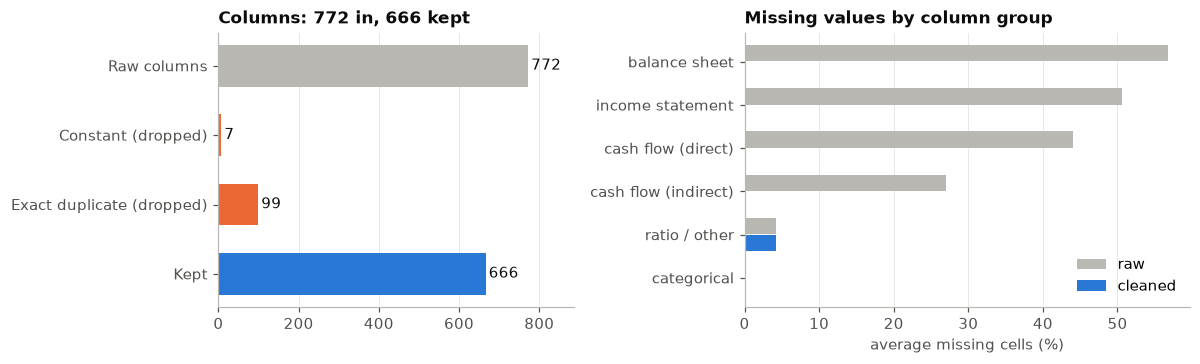

In [6]:
def plot_tabular_cleaning():
    log = pd.read_csv(TAB_OUT_DIR / "cleaning_log.csv")
    action = log["action"].str.replace(r"dropped: identical to .*", "dropped: duplicate", regex=True)
    counts = action.value_counts()
    steps = [("Raw columns", len(log)), ("Constant (dropped)", counts.get("dropped: constant", 0)),
             ("Exact duplicate (dropped)", counts.get("dropped: duplicate", 0)), ("Kept", counts.get("kept", 0))]

    fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1, 1.25]})
    labels, values = zip(*steps)
    colors = [MUTED, ORANGE, ORANGE, BLUE]
    a.barh(labels[::-1], values[::-1], color=colors[::-1], height=0.6)
    for y, v in enumerate(values[::-1]):
        a.text(v + 8, y, f"{v:,}", va="center", color=INK)
    a.set_title("Columns: 772 in, 666 kept")
    a.set_xlim(0, max(values) * 1.15)
    a.grid(axis="y", visible=False)

    groups = log.groupby("group")[["missing_raw", "missing_clean"]].mean().sort_values("missing_raw")
    y = np.arange(len(groups))
    b.barh(y + 0.2, groups["missing_raw"] * 100, height=0.38, color=MUTED, label="raw")
    b.barh(y - 0.2, groups["missing_clean"] * 100, height=0.38, color=BLUE, label="cleaned")
    b.set_yticks(y, groups.index)
    b.set_xlabel("average missing cells (%)")
    b.set_title("Missing values by column group")
    b.legend(loc="lower right")
    b.grid(axis="y", visible=False)
    fig.tight_layout()
    plt.show()


plot_tabular_cleaning()

**Takeaway:** the missing values were mostly in the financial statements. Those blanks meant "not reported", so they became 0. What's left are ratios that can't be calculated (e.g. dividing by zero).

## 2. Load the MD&A text

1. **Read** every `MDA_<year>*.xlsx` file. 2021 and 2022 come in two parts.
2. **Stack** them into one table: `nodeID`, `Year`, `Label` and the text.
3. **Check** the keys and labels against `tabular_clean` from section 1.

No cleaning happens here.

One problem shows up already. Excel stores at most **32,767 characters** in a cell. So any text at exactly that length was cut off when the files were saved, and its ending is lost.

In [7]:
MDA_RAW_DIR = ROOT / "data"
MDA_OUT_DIR = MDA_RAW_DIR / "processed"
MDA_TABULAR_DIR = MDA_OUT_DIR / "tabular_clean"

MDA_KEYS = ["nodeID", "Year", "Label"]
MDA_TEXT = "ManaDiscAnal"
MDA_COLUMNS = MDA_KEYS + [MDA_TEXT]
# Excel caps a cell at 32,767 characters; texts at this length were likely cut off at the source.
MDA_EXCEL_CELL_LIMIT = 32_767


def mda_load_raw() -> pd.DataFrame:
    frames = []
    for year in YEARS:
        files = sorted((MDA_RAW_DIR / str(year)).glob(f"MDA_{year}*.xlsx"))
        assert files, f"{year}: no MD&A file found"
        for path in files:
            frame = pd.read_excel(path)
            assert list(frame.columns) == MDA_COLUMNS, f"{path.name}: unexpected columns"
            assert (frame["Year"] == year).all(), f"{path.name}: Year column disagrees with file"
            frames.append(frame)
    return pd.concat(frames, ignore_index=True)


def mda_check_keys(df: pd.DataFrame) -> None:
    assert df["nodeID"].str.fullmatch(r"L\d{6}").all(), "unexpected nodeID format"
    assert not df.duplicated(["nodeID", "Year"]).any(), "duplicate company-year rows"
    assert df["Label"].isin([0, 1]).all(), "Label must be 0/1"


def check_against_tabular(df: pd.DataFrame) -> None:
    tabular = pd.read_parquet(MDA_TABULAR_DIR, columns=MDA_KEYS)
    merged = df[MDA_KEYS].merge(tabular, on=["nodeID", "Year"], how="outer",
                            suffixes=("_mda", "_tab"), indicator=True)
    only_mda = (merged["_merge"] == "left_only").sum()
    only_tab = (merged["_merge"] == "right_only").sum()
    both = merged[merged["_merge"] == "both"]
    label_mismatch = (both["Label_mda"] != both["Label_tab"]).sum()
    print(f"vs tabular_clean: only in MD&A {only_mda}, only in tabular {only_tab}, "
          f"label mismatches {label_mismatch}")

In [8]:
def run_load_mda() -> None:
    df = mda_load_raw()
    mda_check_keys(df)

    text = df[MDA_TEXT].astype("string")
    empty = text.isna() | (text.str.strip() == "")
    length = text.str.len()
    print(f"rows: {len(df):,}  companies: {df['nodeID'].nunique():,}")
    print(f"fraud rows: {df['Label'].sum():,} ({df['Label'].mean():.2%})")
    print(f"empty/missing text: {empty.sum():,}")
    print(f"text length (chars): median {int(length.median()):,}, max {int(length.max()):,}")
    print(f"texts at Excel cell limit ({MDA_EXCEL_CELL_LIMIT:,} chars): {(length == MDA_EXCEL_CELL_LIMIT).sum():,}")

    if MDA_TABULAR_DIR.exists():
        check_against_tabular(df)
    else:
        print("tabular_clean not found; run section 1 first to cross-check keys")

    df[MDA_TEXT] = text
    MDA_OUT_DIR.mkdir(parents=True, exist_ok=True)
    out = MDA_OUT_DIR / "mda_raw.parquet"
    df.to_parquet(out, index=False)
    print(f"wrote {out.relative_to(ROOT)} ({out.stat().st_size / 1e6:.0f} MB)")

In [9]:
run_load_mda()

rows: 33,664  companies: 5,254
fraud rows: 1,559 (4.63%)
empty/missing text: 513
text length (chars): median 19,222, max 32,767
texts at Excel cell limit (32,767 chars): 3,409
vs tabular_clean: only in MD&A 0, only in tabular 0, label mismatches 0


wrote data/processed/mda_raw.parquet (832 MB)


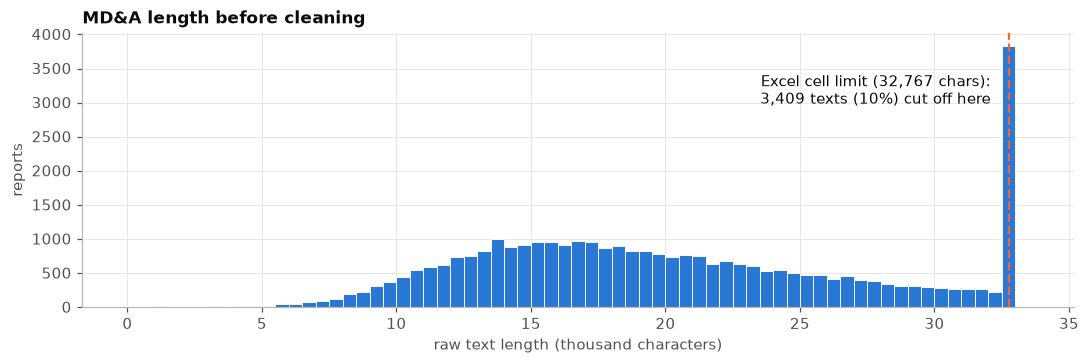

In [10]:
def plot_raw_text_length():
    table = pq.read_table(PROCESSED_DIR / "mda_raw.parquet", columns=["ManaDiscAnal"])
    length = pc.utf8_length(table["ManaDiscAnal"]).to_numpy(zero_copy_only=False)
    length = length[~np.isnan(length.astype(float))]
    capped = int((length == MDA_EXCEL_CELL_LIMIT).sum())

    fig, ax = plt.subplots(figsize=(10, 3.4))
    ax.hist(length / 1000, bins=np.arange(0, 34, 0.5), color=BLUE, edgecolor="white", linewidth=0.6)
    ax.axvline(MDA_EXCEL_CELL_LIMIT / 1000, color=ORANGE, linestyle="--", linewidth=1.5)
    ax.annotate(f"Excel cell limit (32,767 chars):\n{capped:,} texts ({capped / len(length):.0%}) cut off here",
                xy=(MDA_EXCEL_CELL_LIMIT / 1000, ax.get_ylim()[1] * 0.85), xytext=(-12, 0),
                textcoords="offset points", ha="right", va="top", color=INK)
    ax.set_xlabel("raw text length (thousand characters)")
    ax.set_ylabel("reports")
    ax.set_title("MD&A length before cleaning")
    fig.tight_layout()
    plt.show()


plot_raw_text_length()

**Takeaway:** the spike at the right edge is the Excel limit, not real report length. Section 3 flags these reports as `is_truncated = 1`. Because of this, length itself is never used as a feature.

## 3. Clean and split the MD&A text

Each report goes through these steps, in order:

1. **Flag cut-off texts** (`is_truncated = 1`) if the raw text is exactly 32,767 characters. This must happen first, because cleaning changes the length.
2. **Normalise** the characters and remove stray dots and spaces.
3. **Remove boilerplate:** the standard exemption sentence, checkbox lines (√ □ ☑), lines that just say "无", the investor-visit table and short numbered headings.
4. **Rejoin lines** that the PDF conversion broke mid-sentence.
5. **Trim** the half sentence at the end of cut-off texts.
6. **Flag empty texts** (`has_text = 0`) if fewer than 50 characters are left, or no Chinese at all. These rows get empty text.
7. **Split into words** with jieba. First, the sentiment word lists in `data/sentiment/` are added to jieba, so words like 稳健增长 stay whole. If the lists are missing, the cell stops with an error.

The output has three text columns, each built from the one before:
- `text_clean`: the cleaned text. Used for sentiment, readability and embeddings.
- `words`: `text_clean` split into words.
- `tokens`: `words` without stopwords, punctuation and numbers. Used for TF-IDF only.

Each report is cleaned on its own, so nothing here depends on the splits.

In [11]:
jieba.setLogLevel(60)

CLEAN_RAW = ROOT / "data" / "processed" / "mda_raw.parquet"
CLEAN_OUT_DIR = ROOT / "data" / "processed" / "mda_clean"
CLEAN_STOPWORDS_FILE = ROOT / "data" / "stopwords" / "hit_stopwords.txt"
# Yao et al. (2021) formal financial sentiment words, added to jieba so they stay whole
CLEAN_SENTIMENT_FILES = sorted((ROOT / "data" / "sentiment").glob("yao2021_formal_*.txt"))

CLEAN_EXCEL_CELL_LIMIT = 32_767
CLEAN_MIN_CHARS = 50

CLEAN_STOPWORDS = {
    unicodedata.normalize("NFKC", line).strip()
    for line in CLEAN_STOPWORDS_FILE.read_text(encoding="utf-8").splitlines()
} - {""}

if len(CLEAN_SENTIMENT_FILES) != 2:
    raise FileNotFoundError(f"expected 2 sentiment lists in data/sentiment/, found {len(CLEAN_SENTIMENT_FILES)}")
for path in CLEAN_SENTIMENT_FILES:
    jieba.load_userdict(str(path))

CLEAN_CJK = r"一-鿿"
CLEAN_HAS_CJK = re.compile(rf"[{CLEAN_CJK}]")
CLEAN_SPACE_NEXT_TO_CJK = re.compile(rf"(?<=[{CLEAN_CJK}])[ \t]+|[ \t]+(?=[{CLEAN_CJK}])")
CLEAN_DOT_RUN = re.compile(r"\.{4,}")
# B4: standard disclosure-exemption sentence. PDF line breaks can fall anywhere inside it.
CLEAN_EXEMPTION = re.compile(
    r"(?:[一二三四五六七八九十]+、\s*)?"
    + r"\s*".join("公司因不适用准则规定")
    + r"[\s\S]{0,80}?"
    + r"\s*".join("原因说明")
)
CLEAN_CHECKBOX = re.compile(r"[√□☑]")
CLEAN_TOP_HEADING = re.compile(r"^[一二三四五六七八九十]+、")
CLEAN_HEADING = re.compile(r"^(?:[一二三四五六七八九十]+、|\([一二三四五六七八九十\d]+\)|\d{1,2}[、.](?!\d))")
CLEAN_SENTENCE_PUNCT = re.compile(r"[。!?;]")
CLEAN_LINE_END = re.compile(r"[。!?;:][”\"’')\]]*$")
CLEAN_SENTENCE_END = re.compile(r"[。!?][”\"’')\]]*")
CLEAN_PUNCT_ONLY = re.compile(r"^[\W_]+$")
CLEAN_NUMBER = re.compile(r"^[\d.,%]+$")
CLEAN_MAX_HEADING_CHARS = 40


def is_visit_table_heading(line: str) -> bool:
    # B3: the heading itself, not narrative that happens to mention investor visits
    return "接待调研" in line and len(line) < 60 and not CLEAN_SENTENCE_PUNCT.search(line)


def is_heading(line: str) -> bool:
    # B2: short numbered line with no sentence punctuation
    return bool(CLEAN_HEADING.match(line)) and len(line) <= CLEAN_MAX_HEADING_CHARS and not CLEAN_SENTENCE_PUNCT.search(line)


def strip_boilerplate(lines: list[str]) -> list[str]:
    kept, skipping_visits = [], False
    for line in lines:
        if skipping_visits:
            if not CLEAN_TOP_HEADING.match(line):
                continue
            skipping_visits = False
        if is_visit_table_heading(line):
            skipping_visits = True
            continue
        if CLEAN_CHECKBOX.search(line) or line == "无" or is_heading(line):
            continue
        kept.append(line)
    return kept


def rejoin(lines: list[str]) -> str:
    out = ""
    for line in lines:
        if not out or out.endswith("\n"):
            out += line
        elif out[-1].isascii() and out[-1].isalnum() and line[0].isascii() and line[0].isalnum():
            out += " " + line
        else:
            out += line
        if CLEAN_LINE_END.search(line):
            out += "\n"
    return out.strip()


def clean_text(text: str, truncated: bool) -> str:
    text = unicodedata.normalize("NFKC", text).replace("\r\n", "\n").replace("\r", "\n")
    text = CLEAN_DOT_RUN.sub(" ", text)
    text = CLEAN_SPACE_NEXT_TO_CJK.sub("", text)
    text = CLEAN_EXEMPTION.sub("", text)
    lines = [line.strip() for line in text.split("\n")]
    lines = strip_boilerplate([line for line in lines if line])
    text = rejoin(lines)
    if truncated:
        ends = list(CLEAN_SENTENCE_END.finditer(text))
        if ends:
            text = text[: ends[-1].end()]
    return text


def process_report(text: object) -> tuple[int, int, str, str, str]:
    if not isinstance(text, str):
        return 0, 0, "", "", ""
    truncated = int(len(text) == CLEAN_EXCEL_CELL_LIMIT)
    text_clean = clean_text(text, bool(truncated))
    # Too short, or no Chinese at all (garbled encoding in the source): no usable text.
    if len(text_clean) < CLEAN_MIN_CHARS or not CLEAN_HAS_CJK.search(text_clean):
        return 0, truncated, "", "", ""
    words = [w for w in jieba.lcut(text_clean) if w.strip()]
    tokens = [
        w for w in words
        if w not in CLEAN_STOPWORDS and not CLEAN_PUNCT_ONLY.match(w) and not CLEAN_NUMBER.match(w)
    ]
    return 1, truncated, text_clean, " ".join(words), " ".join(tokens)

In [12]:
def run_clean_mda(years: list[int]) -> None:
    CLEAN_OUT_DIR.mkdir(parents=True, exist_ok=True)
    for year in years:
        start = time.time()
        df = pd.read_parquet(CLEAN_RAW, filters=[("Year", "==", year)])
        results = list(map(process_report, df["ManaDiscAnal"]))
        cols = ["has_text", "is_truncated", "text_clean", "words", "tokens"]
        out = df[["nodeID", "Year", "Label"]].copy()
        for i, col in enumerate(cols):
            out[col] = [r[i] for r in results]
        out[["has_text", "is_truncated"]] = out[["has_text", "is_truncated"]].astype("int8")
        out[["text_clean", "words", "tokens"]] = out[["text_clean", "words", "tokens"]].astype("string")
        path = CLEAN_OUT_DIR / f"{year}.parquet"
        out.to_parquet(path, index=False)
        print(
            f"{year}: rows {len(out):,}  has_text=0 {int((out.has_text == 0).sum()):,}  "
            f"is_truncated {int(out.is_truncated.sum()):,}  "
            f"median chars raw->clean {int(df.ManaDiscAnal.str.len().median()):,}->"
            f"{int(out.text_clean.str.len()[out.has_text == 1].median()):,}  "
            f"{path.stat().st_size / 1e6:.0f} MB  {time.time() - start:.0f}s"
        )

In [13]:
run_clean_mda(list(YEARS))

2014: rows 2,631  has_text=0 48  is_truncated 184  median chars raw->clean 19,327->16,805  154 MB  91s


2015: rows 2,824  has_text=0 36  is_truncated 83  median chars raw->clean 15,201->13,274  134 MB  63s


2016: rows 3,125  has_text=0 33  is_truncated 115  median chars raw->clean 16,339->14,201  160 MB  72s


2017: rows 3,503  has_text=0 27  is_truncated 141  median chars raw->clean 16,561->14,376  184 MB  90s


2018: rows 3,596  has_text=0 15  is_truncated 175  median chars raw->clean 16,982->14,822  195 MB  128s


2019: rows 3,815  has_text=0 22  is_truncated 194  median chars raw->clean 17,537->15,240  211 MB  134s


2020: rows 4,269  has_text=0 21  is_truncated 227  median chars raw->clean 17,822->15,316  239 MB  115s


2021: rows 4,769  has_text=0 234  is_truncated 1,019  median chars raw->clean 25,499->22,225  371 MB  188s


2022: rows 5,132  has_text=0 80  is_truncated 1,271  median chars raw->clean 26,440->22,830  423 MB  203s


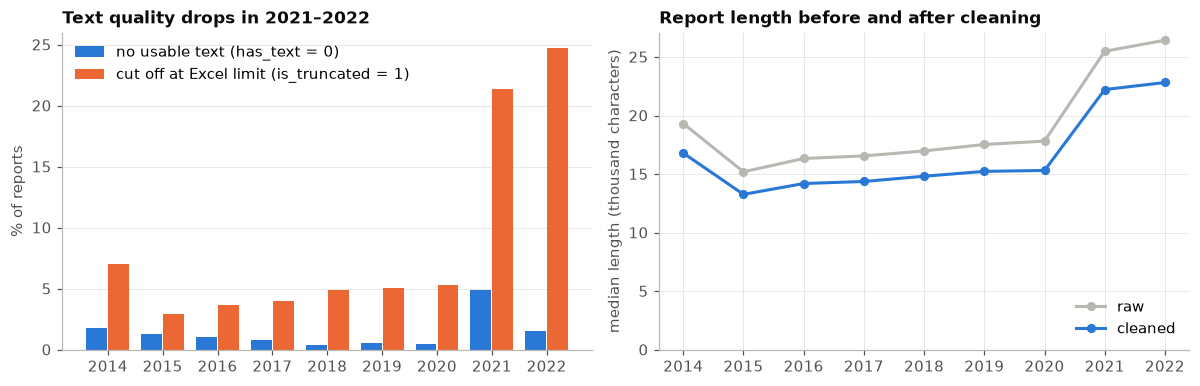

Year     2014  2015  2016  2017  2018  2019  2020  2021  2022
no_text   1.8   1.3   1.1   0.8   0.4   0.6   0.5   4.9   1.6
cut_off   7.0   2.9   3.7   4.0   4.9   5.1   5.3  21.4  24.8


In [14]:
def plot_text_quality():
    cols = ["Year", "has_text", "is_truncated"]
    flags = pd.read_parquet(CLEAN_OUT_DIR, columns=cols)
    by_year = flags.groupby("Year").agg(no_text=("has_text", lambda s: (s == 0).mean() * 100),
                                        cut_off=("is_truncated", "mean"))
    by_year["cut_off"] *= 100

    raw = pq.read_table(CLEAN_RAW, columns=["Year", "ManaDiscAnal"])
    raw_len = pd.DataFrame({"Year": raw["Year"].to_numpy(),
                            "raw": pc.utf8_length(raw["ManaDiscAnal"]).to_numpy(zero_copy_only=False)})
    clean_len = []
    for year in YEARS:
        t = pq.read_table(CLEAN_OUT_DIR / f"{year}.parquet", columns=["has_text", "text_clean"])
        keep = t["has_text"].to_numpy() == 1
        clean_len.append(np.median(pc.utf8_length(t["text_clean"]).to_numpy(zero_copy_only=False)[keep]))
    medians = pd.DataFrame({"raw": raw_len.groupby("Year")["raw"].median(), "cleaned": clean_len}, index=list(YEARS))

    fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.6))
    x = np.arange(len(by_year))
    a.bar(x - 0.2, by_year["no_text"], width=0.38, color=BLUE, label="no usable text (has_text = 0)")
    a.bar(x + 0.2, by_year["cut_off"], width=0.38, color=ORANGE, label="cut off at Excel limit (is_truncated = 1)")
    a.set_xticks(x, by_year.index)
    a.set_ylabel("% of reports")
    a.set_title("Text quality drops in 2021–2022")
    a.legend(loc="upper left")
    a.grid(axis="x", visible=False)

    b.plot(medians.index, medians["raw"] / 1000, color=MUTED, marker="o", markersize=5, label="raw")
    b.plot(medians.index, medians["cleaned"] / 1000, color=BLUE, marker="o", markersize=5, label="cleaned")
    b.set_ylabel("median length (thousand characters)")
    b.set_title("Report length before and after cleaning")
    b.set_ylim(0, None)
    b.legend(loc="lower right")
    fig.tight_layout()
    plt.show()
    print(by_year.round(1).T.to_string())


plot_text_quality()

**Takeaway:** 2021 and 2022 have many more cut-off and empty reports. These are the last two test years, so text features are weaker exactly where the model is tested. That's why results should be reported per split.

Cleaning shortens every year by about the same amount, so it removes boilerplate without changing the trend.